# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Muhammad Zaki Nanda Wahyudi | 5054251007 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [29]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.

# Load dataset
df = pd.read_csv("Live.csv")

# Informasi dasar dataset
print("Jumlah baris dan kolom:", df.shape)
print("\nJumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

# Tipe data setiap kolom
print("\nTipe Data:")
print(df.dtypes)

# Statistik deskriptif
print("\nStatistik Deskriptif:")
print(df.describe(include="all"))

# Jumlah missing value setiap kolom
print("\nJumlah Missing Value:")
print(df.isnull().sum())

# Kolom yang seluruh nilainya kosong
print("\nKolom yang Seluruhnya Kosong:")
print(df.columns[df.isnull().all()].tolist())

# Total missing value
print("\nTotal Missing Value:", df.isnull().sum().sum())

# Jumlah baris duplikat
print("\nJumlah Baris Duplikat:", df.duplicated().sum())

Jumlah baris dan kolom: (7050, 16)

Jumlah baris: 7050
Jumlah kolom: 16

Tipe Data:
status_id             int64
status_type             str
status_published        str
num_reactions         int64
num_comments          int64
num_shares            int64
num_likes             int64
num_loves             int64
num_wows              int64
num_hahas             int64
num_sads              int64
num_angrys            int64
Column1             float64
Column2             float64
Column3             float64
Column4             float64
dtype: object

Statistik Deskriptif:
          status_id status_type status_published  num_reactions  num_comments  \
count   7050.000000        7050             7050    7050.000000   7050.000000   
unique          NaN           4             6913            NaN           NaN   
top             NaN       photo   3/20/2018 1:54            NaN           NaN   
freq            NaN        4288                3            NaN           NaN   
mean    3525.500000       

Statistik Distribusi Fitur Hitungan:
               Skewness  Jumlah Nol  Proporsi Nol (%)  Minimum  Maksimum  \
num_reactions      3.74         121              1.72        0      4710   
num_comments       9.03        2119             30.06        0     20990   
num_shares         7.10        3911             55.48        0      3424   
num_likes          3.92         126              1.79        0      4710   
num_loves          6.00        4230             60.00        0       657   
num_wows          18.25        5308             75.29        0       278   
num_hahas         20.31        5916             83.91        0       157   
num_sads          17.58        6443             91.39        0        51   
num_angrys        19.51        6627             94.00        0        31   

                 Mean     Std  
num_reactions  230.12  462.63  
num_comments   224.36  889.64  
num_shares      40.02  131.60  
num_likes      215.04  449.47  
num_loves       12.73   39.97  
num_wows  

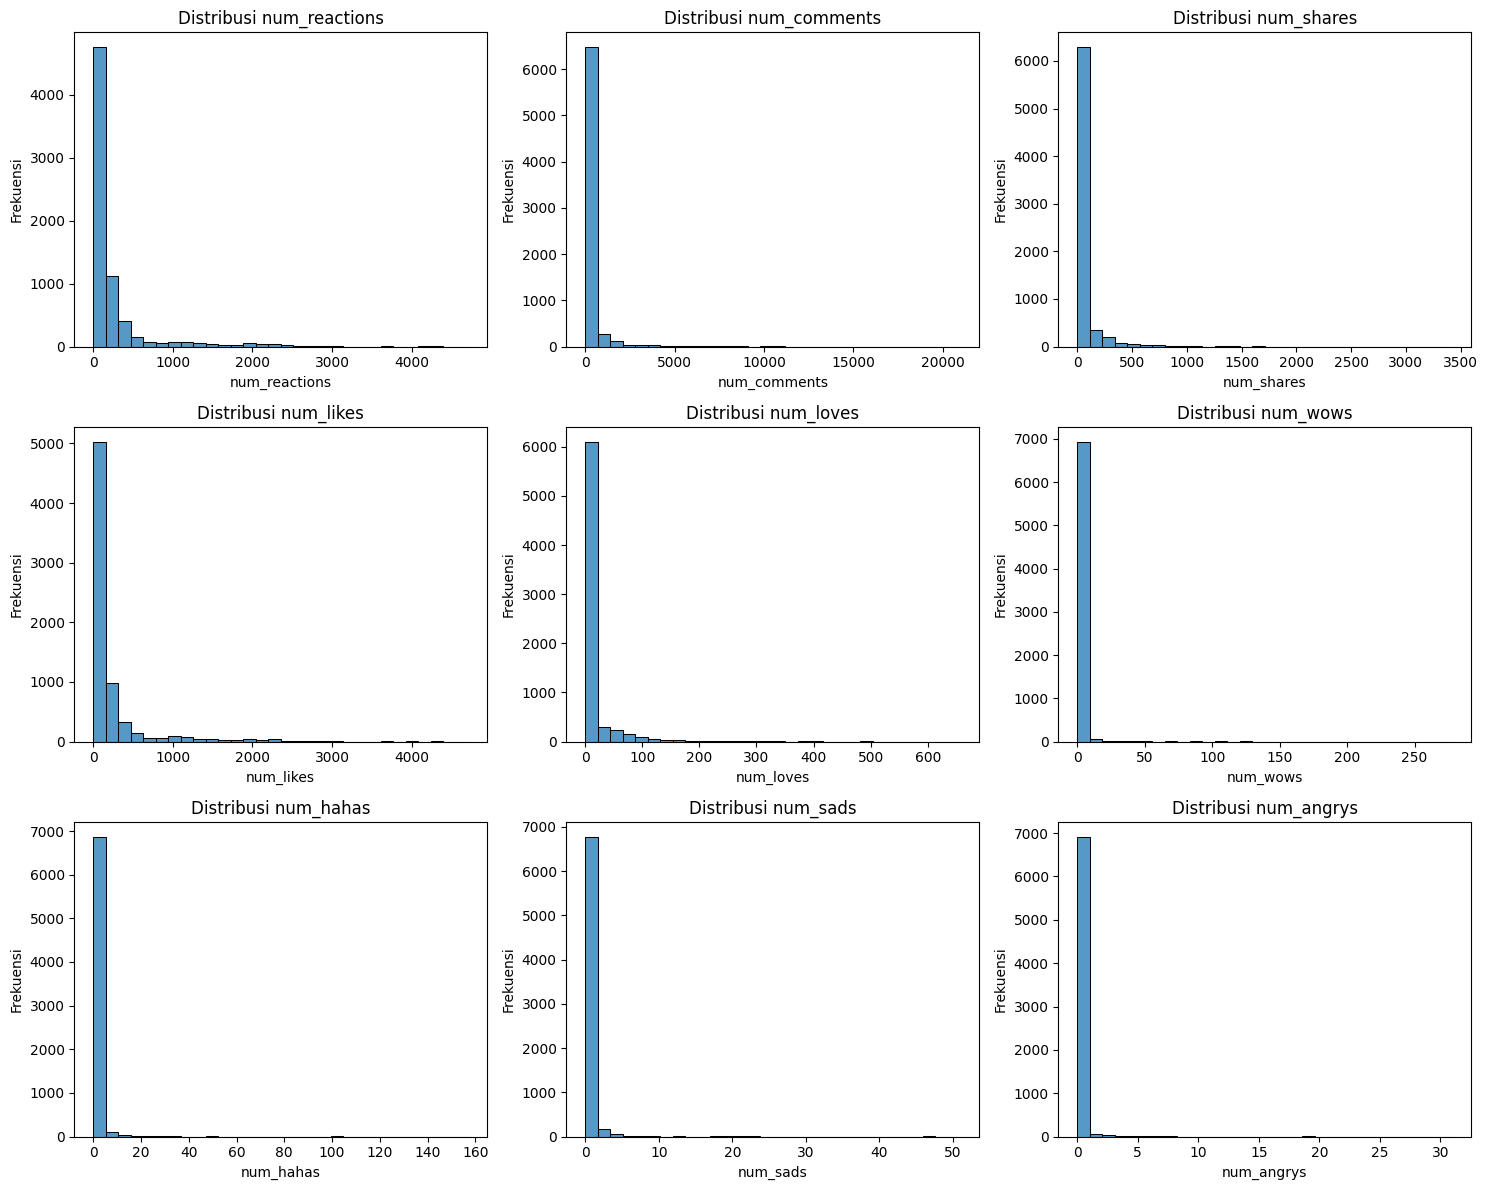

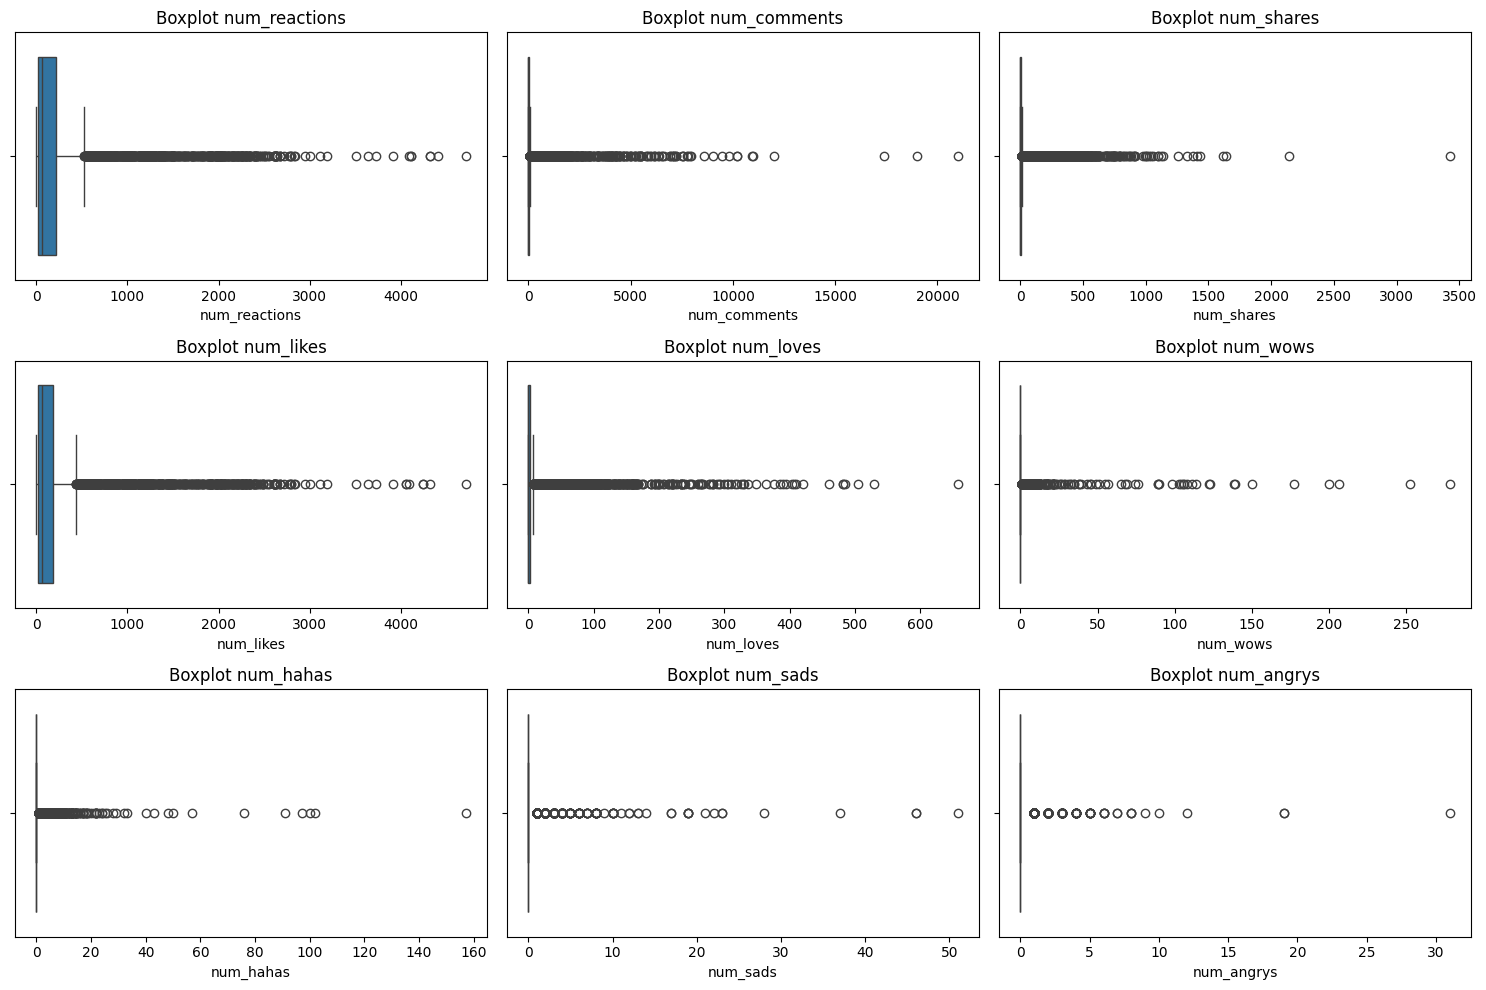

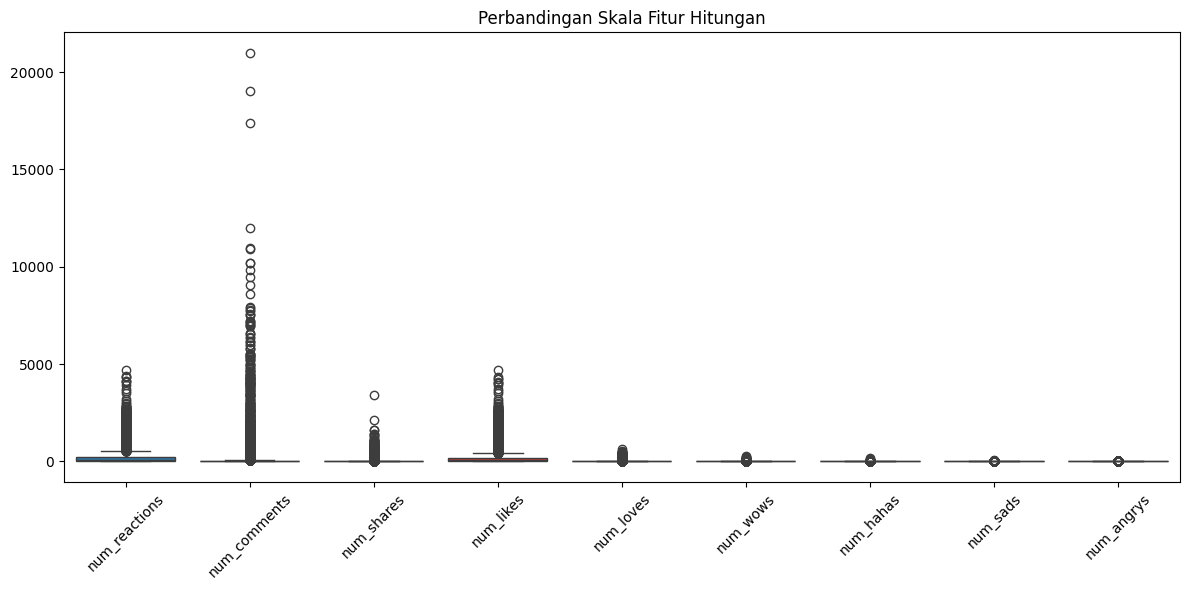

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.

# Pilih fitur hitungan
fitur_hitungan = [
    "num_reactions", "num_comments", "num_shares", "num_likes",
    "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"
]

# Statistik distribusi fitur
distribusi = pd.DataFrame({
    "Skewness": df[fitur_hitungan].skew(),
    "Jumlah Nol": (df[fitur_hitungan] == 0).sum(),
    "Proporsi Nol (%)": (df[fitur_hitungan] == 0).mean() * 100,
    "Minimum": df[fitur_hitungan].min(),
    "Maksimum": df[fitur_hitungan].max(),
    "Mean": df[fitur_hitungan].mean(),
    "Std": df[fitur_hitungan].std()
})

print("Statistik Distribusi Fitur Hitungan:")
print(distribusi.round(2))

# Histogram setiap fitur
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, fitur in enumerate(fitur_hitungan):
    sns.histplot(data=df, x=fitur, bins=30, ax=axes[i])
    axes[i].set_title(f"Distribusi {fitur}")
    axes[i].set_xlabel(fitur)
    axes[i].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

# Boxplot setiap fitur
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, fitur in enumerate(fitur_hitungan):
    sns.boxplot(data=df, x=fitur, ax=axes[i])
    axes[i].set_title(f"Boxplot {fitur}")

plt.tight_layout()
plt.show()

# Perbandingan skala antar fitur
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[fitur_hitungan])
plt.title("Perbandingan Skala Fitur Hitungan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

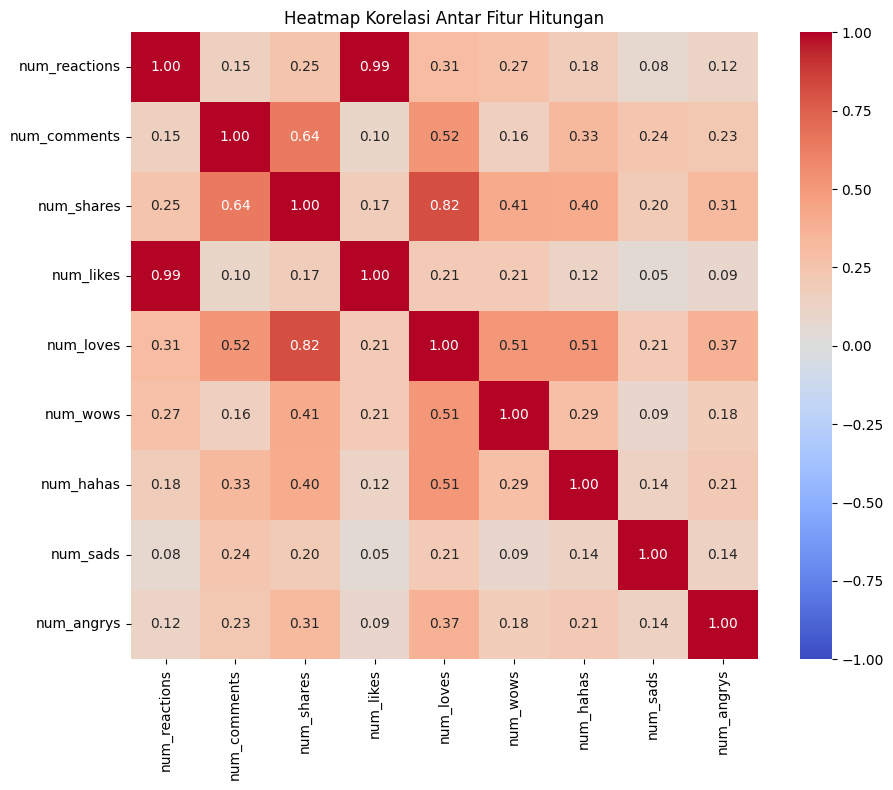

In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.

# Heatmap korelasi antar fitur hitungan
korelasi = df[fitur_hitungan].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Heatmap Korelasi Antar Fitur Hitungan")
plt.tight_layout()
plt.show()

       jumlah_posting  posting_dengan_emoji  proporsi_emoji (%)
tahun                                                          
2012              589                     0                0.00
2013              500                     0                0.00
2014              233                     0                0.00
2015              337                     0                0.00
2016              588                   400               68.03
2017             2253                  1221               54.19
2018             2550                  1473               57.76


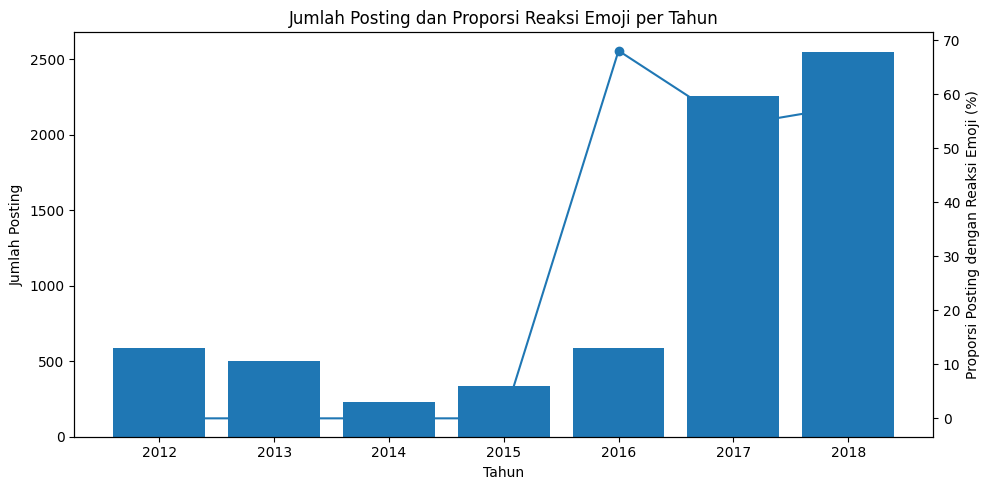

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.

# Ubah status_published menjadi datetime
df["status_published"] = pd.to_datetime(
    df["status_published"], errors="coerce"
)

# Ambil tahun posting
df["tahun"] = df["status_published"].dt.year

# Kolom reaksi emoji (selain likes)
kolom_emoji = [
    "num_loves", "num_wows", "num_hahas",
    "num_sads", "num_angrys"
]

# Tandai posting yang memiliki minimal satu reaksi emoji
df["ada_reaksi_emoji"] = (df[kolom_emoji].sum(axis=1) > 0)

# Jumlah posting dan proporsi posting dengan reaksi emoji per tahun
ringkasan_tahunan = df.groupby("tahun").agg(
    jumlah_posting=("status_id", "count"),
    posting_dengan_emoji=("ada_reaksi_emoji", "sum")
)

ringkasan_tahunan["proporsi_emoji (%)"] = (
    ringkasan_tahunan["posting_dengan_emoji"]
    / ringkasan_tahunan["jumlah_posting"] * 100
)

print(ringkasan_tahunan.round(2))

# Visualisasi perubahan pola dari tahun ke tahun
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(
    ringkasan_tahunan.index.astype(str),
    ringkasan_tahunan["jumlah_posting"]
)
ax1.set_xlabel("Tahun")
ax1.set_ylabel("Jumlah Posting")

ax2 = ax1.twinx()
ax2.plot(
    ringkasan_tahunan.index.astype(str),
    ringkasan_tahunan["proporsi_emoji (%)"],
    marker="o"
)
ax2.set_ylabel("Proporsi Posting dengan Reaksi Emoji (%)")

plt.title("Jumlah Posting dan Proporsi Reaksi Emoji per Tahun")
plt.tight_layout()
plt.show()

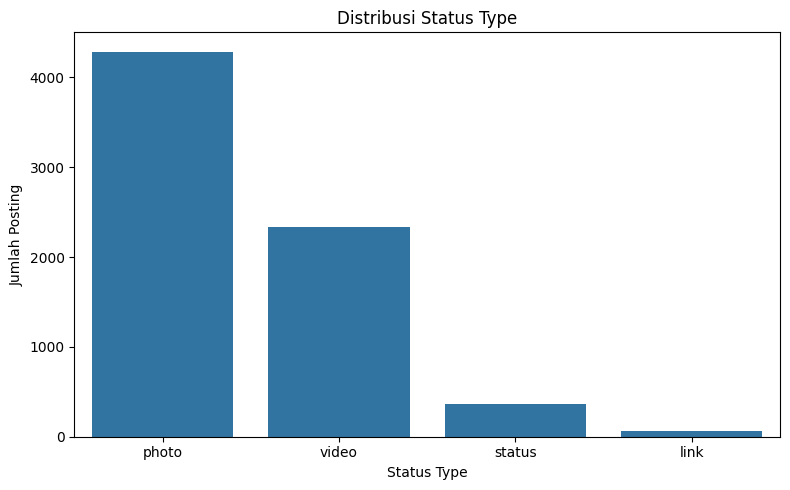

Median Interaksi Berdasarkan Status Type:
             num_likes  num_comments  num_shares
status_type                                     
link              48.0           1.0         0.0
photo             34.0           2.0         0.0
status           117.0          10.0         0.0
video            117.0          39.0        12.0


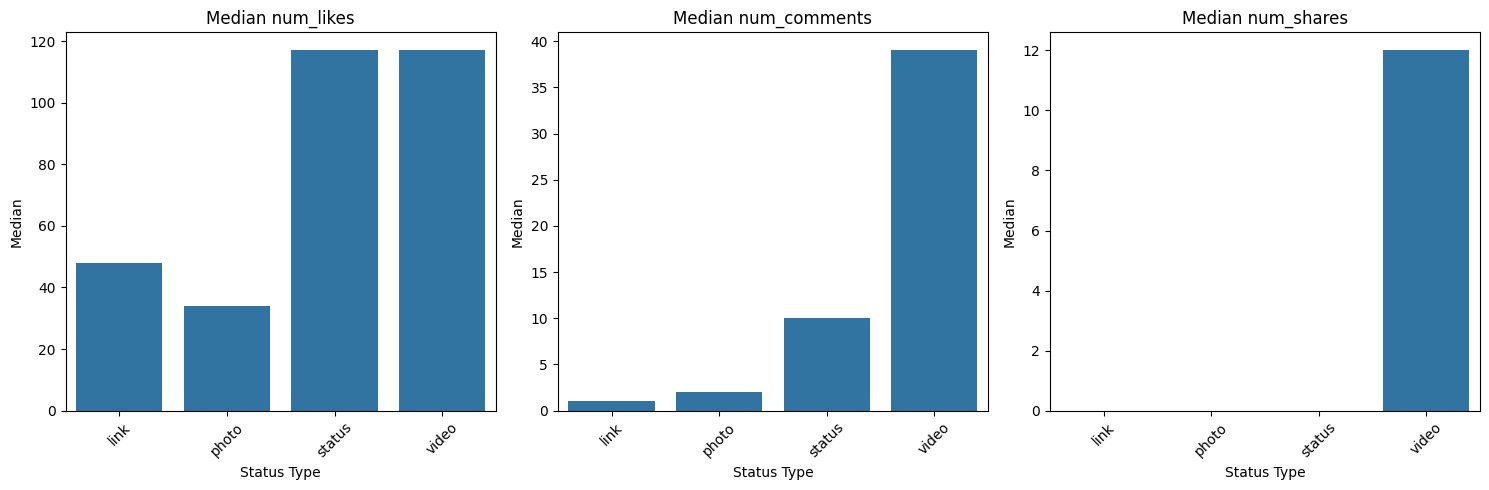

In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.

# Distribusi status_type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="status_type", order=df["status_type"].value_counts().index)
plt.title("Distribusi Status Type")
plt.xlabel("Status Type")
plt.ylabel("Jumlah Posting")
plt.tight_layout()
plt.show()

# Median likes, comments, dan shares untuk setiap status_type
median_status = df.groupby("status_type")[
    ["num_likes", "num_comments", "num_shares"]
].median()

print("Median Interaksi Berdasarkan Status Type:")
print(median_status)

# Visualisasi perbandingan median
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, fitur in zip(axes, ["num_likes", "num_comments", "num_shares"]):
    sns.barplot(x=median_status.index, y=median_status[fitur], ax=ax)
    ax.set_title(f"Median {fitur}")
    ax.set_xlabel("Status Type")
    ax.set_ylabel("Median")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [7]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.

# 1. Hapus kolom yang seluruhnya kosong
kolom_kosong = df.columns[df.isna().all()].tolist()
print("Kolom yang dihapus:", kolom_kosong)

df = df.drop(columns=kolom_kosong)

# 2. Periksa dan tangani baris duplikat
print("\nJumlah baris duplikat:", df.duplicated().sum())
print("Jumlah status_id duplikat:", df["status_id"].duplicated().sum())

df = df.drop_duplicates()

# 3. Periksa missing value
print("\nMissing value sebelum penanganan:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Isi missing value pada fitur hitungan dengan median
fitur_hitungan = [
    "num_reactions", "num_comments", "num_shares", "num_likes",
    "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"
]

for kolom in fitur_hitungan:
    if df[kolom].isnull().any():
        df[kolom] = df[kolom].fillna(df[kolom].median())

# Isi missing value status_type dengan modus
if df["status_type"].isnull().any():
    df["status_type"] = df["status_type"].fillna(
        df["status_type"].mode()[0]
    )

# Hapus baris dengan tanggal tidak valid jika ada
if "status_published" in df.columns:
    jumlah_tanggal_invalid = df["status_published"].isnull().sum()
    print("\nTanggal tidak valid:", jumlah_tanggal_invalid)

    if jumlah_tanggal_invalid > 0:
        df = df.dropna(subset=["status_published"])

print("\nMissing value setelah penanganan:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 4. Periksa dan tangani outlier ekstrem menggunakan batas 3 × IQR
print("\nPemeriksaan dan penanganan outlier ekstrem:")

for kolom in fitur_hitungan:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    if IQR > 0:
        batas_bawah = Q1 - 3 * IQR
        batas_atas = Q3 + 3 * IQR

        jumlah_outlier = (
            (df[kolom] < batas_bawah) |
            (df[kolom] > batas_atas)
        ).sum()

        print(f"{kolom}: {jumlah_outlier} outlier ekstrem")

        # Capping agar baris tidak perlu dihapus
        df[kolom] = df[kolom].clip(
            lower=max(0, batas_bawah),
            upper=batas_atas
        )
    else:
        print(
            f"{kolom}: IQR = 0, tidak dilakukan capping "
            "agar variasi nilai tidak hilang."
        )

# 5. Periksa kondisi akhir dataset
print("\nUkuran dataset setelah preprocessing:", df.shape)
print("Jumlah baris duplikat tersisa:", df.duplicated().sum())
print("Total missing value tersisa:", df.isnull().sum().sum())

Kolom yang dihapus: ['Column1', 'Column2', 'Column3', 'Column4']

Jumlah baris duplikat: 0
Jumlah status_id duplikat: 0

Missing value sebelum penanganan:
Series([], dtype: int64)

Tanggal tidak valid: 0

Missing value setelah penanganan:
Series([], dtype: int64)

Pemeriksaan dan penanganan outlier ekstrem:
num_reactions: 526 outlier ekstrem
num_comments: 1250 outlier ekstrem
num_shares: 1243 outlier ekstrem
num_likes: 555 outlier ekstrem
num_loves: 1138 outlier ekstrem
num_wows: IQR = 0, tidak dilakukan capping agar variasi nilai tidak hilang.
num_hahas: IQR = 0, tidak dilakukan capping agar variasi nilai tidak hilang.
num_sads: IQR = 0, tidak dilakukan capping agar variasi nilai tidak hilang.
num_angrys: IQR = 0, tidak dilakukan capping agar variasi nilai tidak hilang.

Ukuran dataset setelah preprocessing: (7050, 14)
Jumlah baris duplikat tersisa: 0
Total missing value tersisa: 0


In [8]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.

# 1. Pisahkan kolom untuk interpretasi cluster
metadata = df[["status_type", "status_published"]].copy()

# 2. Hapus kolom ID dan kolom bantu yang tidak digunakan
df_precluster = df.drop(
    columns=[
        "status_id", "status_type", "status_published",
        "tahun", "ada_reaksi_emoji"
    ],
    errors="ignore"
).copy()

# 3. Periksa redundansi fitur reaksi
kolom_reaksi = [
    "num_likes", "num_loves", "num_wows",
    "num_hahas", "num_sads", "num_angrys"
]

total_reaksi = df[kolom_reaksi].sum(axis=1)

print("Pemeriksaan redundansi:")
print(
    "Jumlah baris num_reactions sama dengan jumlah komponennya:",
    (df["num_reactions"] == total_reaksi).sum(),
    "dari", len(df), "baris"
)

print("\nKorelasi antarfitur hitungan:")
print(df[fitur_hitungan].corr().round(2))

# 4. Periksa proporsi nilai nol
proporsi_nol = (df[fitur_hitungan] == 0).mean() * 100

print("\nProporsi nilai nol (%):")
print(proporsi_nol.round(2).sort_values(ascending=False))

# 5. Gabungkan fitur reaksi yang sparse
df_precluster["num_rare_reactions"] = df[
    ["num_wows", "num_hahas", "num_sads", "num_angrys"]
].sum(axis=1)

# 6. Pilih fitur untuk clustering
# num_reactions tidak digunakan karena redundan dengan komponen reaksi.
# Fitur reaksi langka digabungkan menjadi satu fitur.
fitur_clustering = [
    "num_likes",
    "num_loves",
    "num_rare_reactions",
    "num_comments",
    "num_shares"
]

X = df_precluster[fitur_clustering].copy()

# Pastikan seluruh fitur berupa angka
X = X.select_dtypes(include=[np.number])

print("\nFitur yang digunakan untuk clustering:")
print(X.columns.tolist())

print("\nUkuran data clustering:", X.shape)
print("\nTipe data fitur:")
print(X.dtypes)

print("\nMissing value pada fitur clustering:")
print(X.isnull().sum())

print("\nContoh data fitur clustering:")
print(X.head())

Pemeriksaan redundansi:
Jumlah baris num_reactions sama dengan jumlah komponennya: 5497 dari 7050 baris

Korelasi antarfitur hitungan:
               num_reactions  num_comments  num_shares  num_likes  num_loves  \
num_reactions           1.00          0.43        0.37       0.99       0.37   
num_comments            0.43          1.00        0.84       0.38       0.84   
num_shares              0.37          0.84        1.00       0.32       0.78   
num_likes               0.99          0.38        0.32       1.00       0.32   
num_loves               0.37          0.84        0.78       0.32       1.00   
num_wows                0.27          0.21        0.19       0.26       0.23   
num_hahas               0.22          0.28        0.30       0.19       0.28   
num_sads                0.12          0.15        0.15       0.11       0.17   
num_angrys              0.17          0.24        0.21       0.15       0.21   

               num_wows  num_hahas  num_sads  num_angrys  
num_r

**Fitur yang dipilih untuk clustering:** num_likes, num_loves, num_rare_reactions, num_comments, dan num_shares, dengan pertimbangan berikut:

| Fitur                | Alasan Pemilihan                                                                                                                                               |
| -------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `num_likes`          | Mewakili jumlah likes dan memiliki proporsi nilai nol yang rendah, yaitu 1,79%.                                                                                |
| `num_loves`          | Mewakili reaksi love yang dapat membedakan pola interaksi pengguna. Meskipun 60% bernilai nol, fitur ini tetap dipertahankan karena memiliki makna tersendiri. |
| `num_rare_reactions` | Gabungan `num_wows`, `num_hahas`, `num_sads`, dan `num_angrys` untuk mengurangi jumlah fitur yang sangat sparse atau didominasi nilai nol.                     |
| `num_comments`       | Mewakili jumlah komentar sebagai bentuk interaksi pengguna. Sebanyak 30,06% bernilai nol, tetapi fitur ini tetap relevan.                                      |
| `num_shares`         | Mewakili jumlah pembagian posting. Walaupun 55,48% bernilai nol, fitur ini menunjukkan tingkat penyebaran konten.                                              |

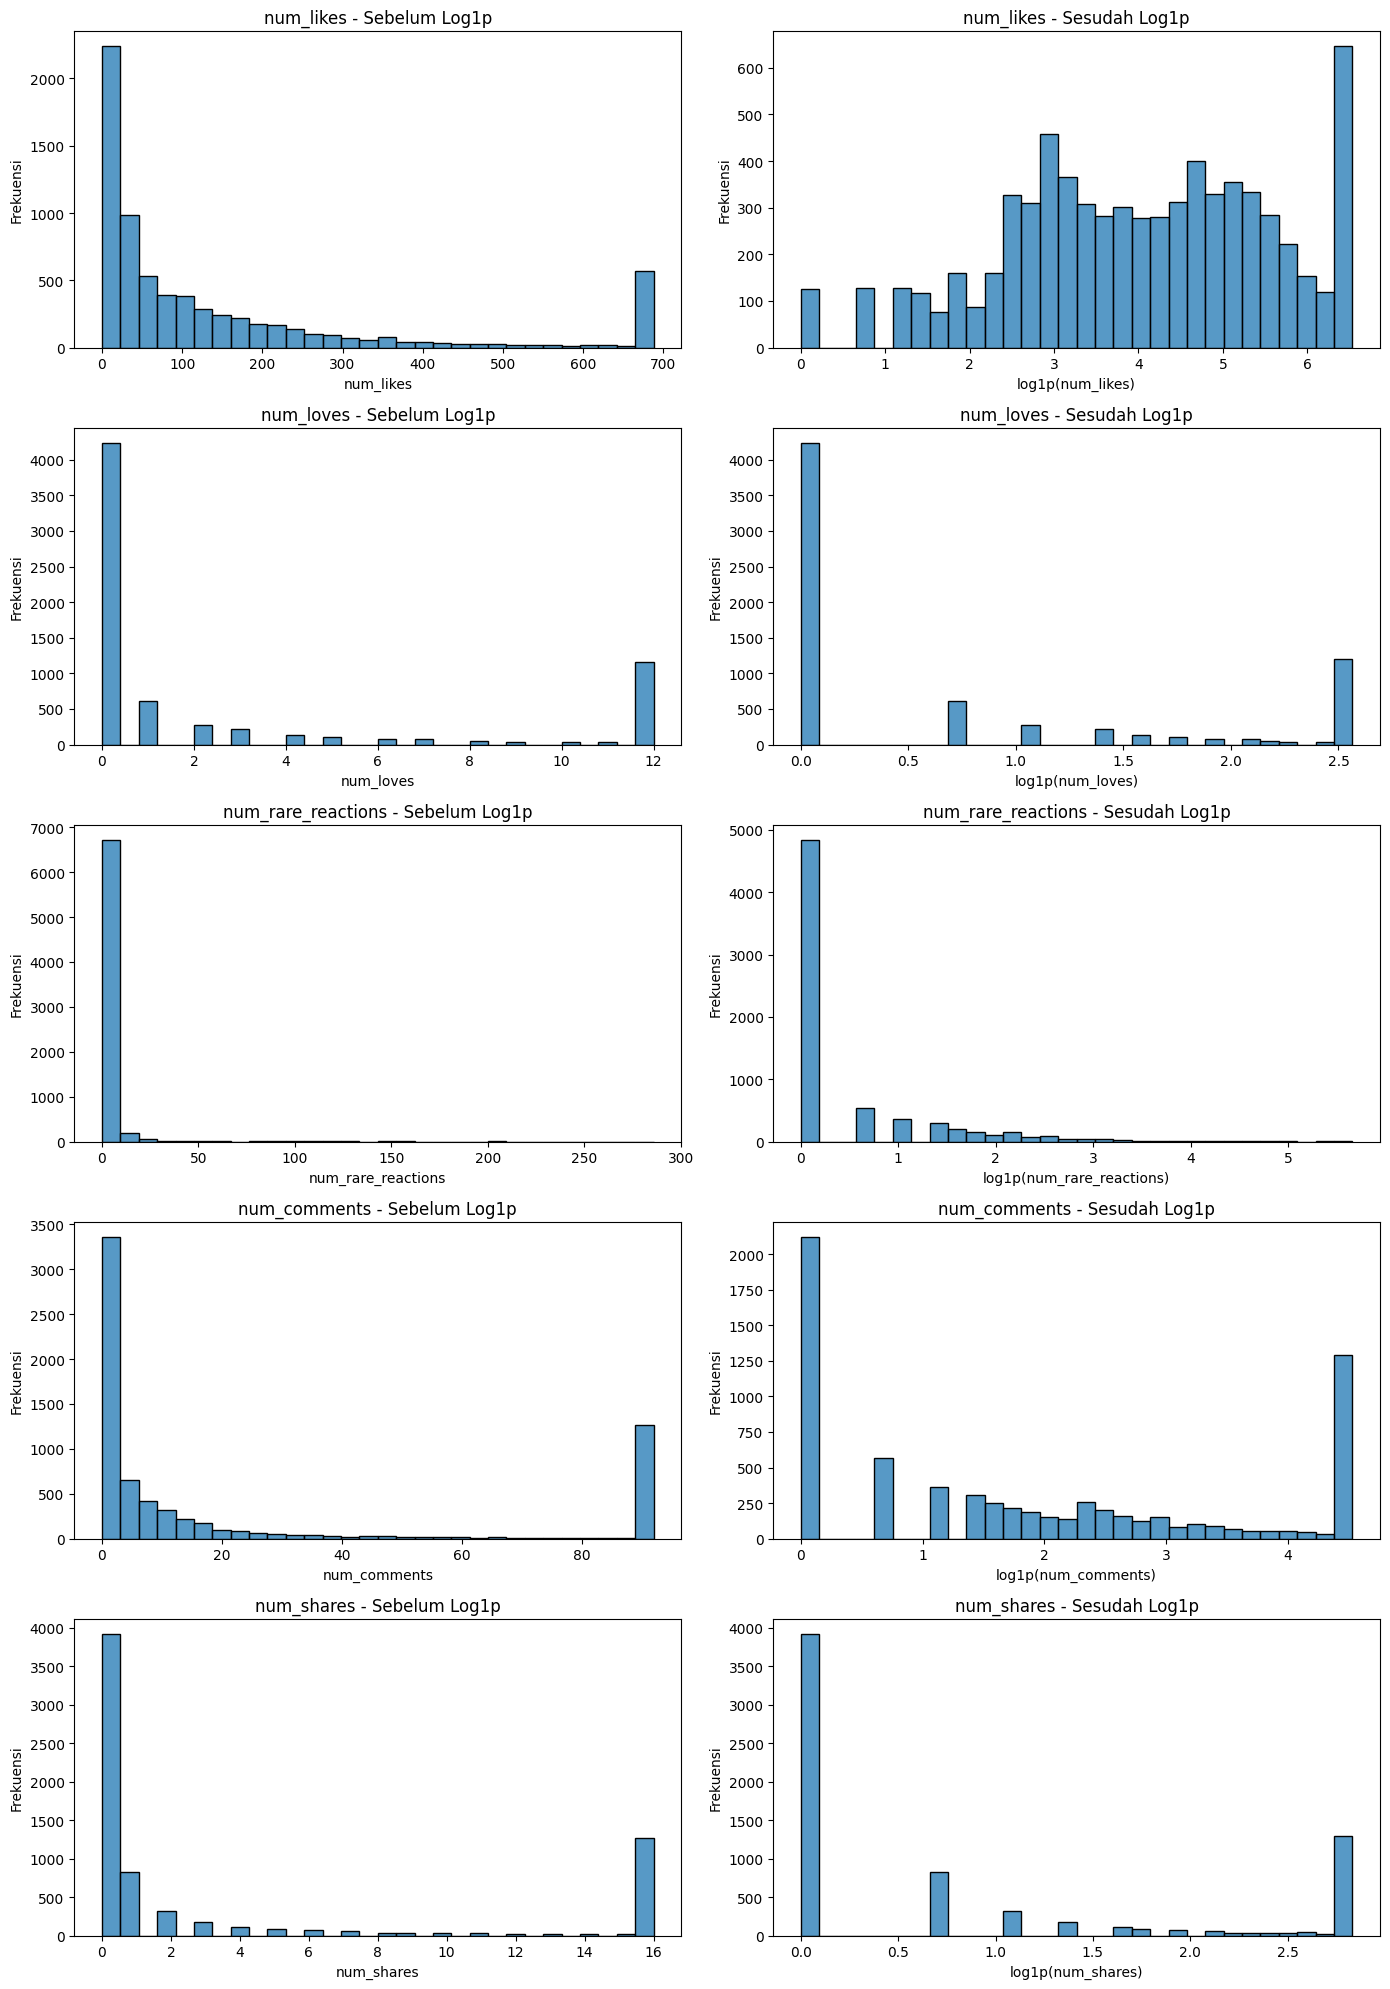

In [9]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.

# Transformasi log1p pada fitur yang dipilih
X_log = np.log1p(X)

# Tampilkan distribusi sebelum dan sesudah transformasi
fig, axes = plt.subplots(len(fitur_clustering), 2, figsize=(14, 20))

for i, fitur in enumerate(fitur_clustering):
    sns.histplot(X[fitur], bins=30, ax=axes[i, 0])
    axes[i, 0].set_title(f"{fitur} - Sebelum Log1p")
    axes[i, 0].set_xlabel(fitur)
    axes[i, 0].set_ylabel("Frekuensi")

    sns.histplot(X_log[fitur], bins=30, ax=axes[i, 1])
    axes[i, 1].set_title(f"{fitur} - Sesudah Log1p")
    axes[i, 1].set_xlabel(f"log1p({fitur})")
    axes[i, 1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

In [10]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja

# X_raw: fitur mentah tanpa transformasi dan tanpa scaling
X_raw = X.copy()

# X_raw_scaled: fitur mentah dengan scaling saja
scaler_raw = StandardScaler()
X_raw_scaled = pd.DataFrame(
    scaler_raw.fit_transform(X_raw),
    columns=X_raw.columns,
    index=X_raw.index
)

# X_log_scaled: fitur hasil log1p dengan scaling
scaler_log = StandardScaler()
X_log_scaled = pd.DataFrame(
    scaler_log.fit_transform(X_log),
    columns=X_log.columns,
    index=X_log.index
)

# Periksa hasil
print("X_raw:", X_raw.shape)
print("X_raw_scaled:", X_raw_scaled.shape)
print("X_log_scaled:", X_log_scaled.shape)

print("\nContoh X_log_scaled:")
print(X_log_scaled.head())

X_raw: (7050, 5)
X_raw_scaled: (7050, 5)
X_log_scaled: (7050, 5)

Contoh X_log_scaled:
   num_likes  num_loves  num_rare_reactions  num_comments  num_shares
0   1.301528   1.824598            1.478523      1.582252    1.782023
1   0.637887  -0.715763           -0.570394     -1.113953   -0.749813
2   0.830486   1.824598            0.685894      1.582252    1.782023
3   0.449666  -0.715763           -0.570394     -1.113953   -0.749813
4   0.830486   1.564749           -0.570394     -1.113953   -0.749813


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [11]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.

# Latih K-Means dengan k=3 pada tiga versi data
k = 3

kmeans_raw = KMeans(n_clusters=k, random_state=42, n_init=10)
label_raw = kmeans_raw.fit_predict(X_raw)

kmeans_raw_scaled = KMeans(n_clusters=k, random_state=42, n_init=10)
label_raw_scaled = kmeans_raw_scaled.fit_predict(X_raw_scaled)

kmeans_log_scaled = KMeans(n_clusters=k, random_state=42, n_init=10)
label_log_scaled = kmeans_log_scaled.fit_predict(X_log_scaled)

Jumlah dan Proporsi Anggota Cluster:

X_raw:
   Jumlah Anggota  Proporsi (%)
0            4762         67.55
1             770         10.92
2            1518         21.53

X_raw_scaled:
   Jumlah Anggota  Proporsi (%)
0            1389         19.70
1            5629         79.84
2              32          0.45

X_log_scaled:
   Jumlah Anggota  Proporsi (%)
0            3328         47.21
1            1486         21.08
2            2236         31.72

Silhouette Score pada X_log_scaled:
X_raw: 0.2938
X_raw_scaled: 0.5014
X_log_scaled: 0.4046

Varians Fitur Mentah:
                     Varians  Kontribusi Varians (%)
num_likes           39848.74                   96.66
num_comments         1194.91                    2.90
num_rare_reactions    122.70                    0.30
num_shares             37.88                    0.09
num_loves              20.39                    0.05


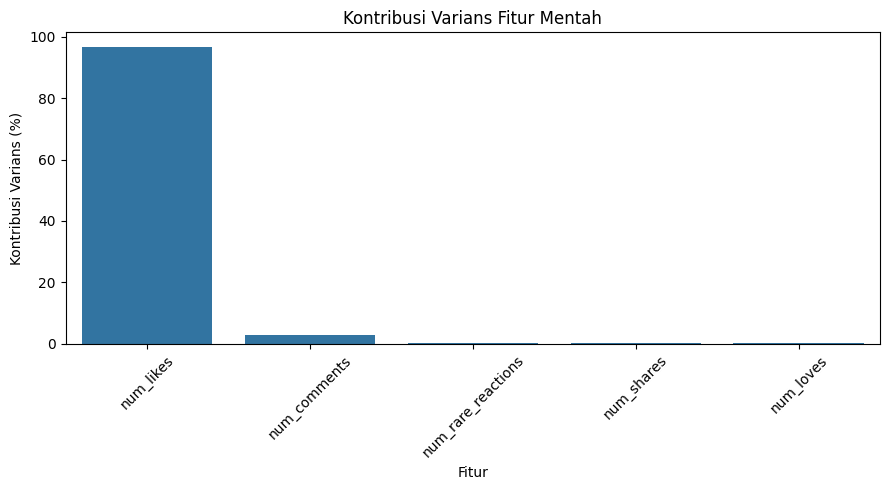


X_raw:
Cluster terkecil: 1 (770 anggota, 10.92%)
Cluster terbesar: 0 (4762 anggota, 67.55%)

X_raw_scaled:
Cluster terkecil: 2 (32 anggota, 0.45%)
Cluster terbesar: 1 (5629 anggota, 79.84%)

X_log_scaled:
Cluster terkecil: 1 (1486 anggota, 21.08%)
Cluster terbesar: 0 (3328 anggota, 47.21%)


In [12]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.

# 1. Bandingkan jumlah anggota tiap cluster
hasil_cluster = {
    "X_raw": label_raw,
    "X_raw_scaled": label_raw_scaled,
    "X_log_scaled": label_log_scaled
}

print("Jumlah dan Proporsi Anggota Cluster:")
for nama, label in hasil_cluster.items():
    jumlah = pd.Series(label).value_counts().sort_index()
    proporsi = (jumlah / len(label) * 100).round(2)

    print(f"\n{nama}:")
    print(pd.DataFrame({
        "Jumlah Anggota": jumlah,
        "Proporsi (%)": proporsi
    }))

# 2. Bandingkan Silhouette Score pada ruang yang sama
print("\nSilhouette Score pada X_log_scaled:")
for nama, label in hasil_cluster.items():
    skor = silhouette_score(X_log_scaled, label)
    print(f"{nama}: {skor:.4f}")

# 3. Periksa varians fitur mentah untuk melihat fitur yang mendominasi
varians = X_raw.var()
persentase_varians = varians / varians.sum() * 100

ringkasan_varians = pd.DataFrame({
    "Varians": varians,
    "Kontribusi Varians (%)": persentase_varians
}).sort_values("Varians", ascending=False)

print("\nVarians Fitur Mentah:")
print(ringkasan_varians.round(2))

# Visualisasi kontribusi varians fitur mentah
plt.figure(figsize=(9, 5))
sns.barplot(
    x=ringkasan_varians.index,
    y=ringkasan_varians["Kontribusi Varians (%)"]
)
plt.title("Kontribusi Varians Fitur Mentah")
plt.xlabel("Fitur")
plt.ylabel("Kontribusi Varians (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Identifikasi cluster terkecil dan terbesar
for nama, label in hasil_cluster.items():
    jumlah = pd.Series(label).value_counts().sort_index()
    cluster_terkecil = jumlah.idxmin()
    cluster_terbesar = jumlah.idxmax()

    print(f"\n{nama}:")
    print(
        f"Cluster terkecil: {cluster_terkecil} "
        f"({jumlah.min()} anggota, {jumlah.min() / len(label) * 100:.2f}%)"
    )
    print(
        f"Cluster terbesar: {cluster_terbesar} "
        f"({jumlah.max()} anggota, {jumlah.max() / len(label) * 100:.2f}%)"
    )

## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.

# Latih K-Means pada X_log_scaled untuk k = 2 sampai 10
inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_log_scaled)

    inertia_values.append({
        "k": k,
        "inertia": kmeans.inertia_
    })

# Simpan dan tampilkan nilai inertia
inertia_df = pd.DataFrame(inertia_values)
print(inertia_df)

    k       inertia
0   2  16113.285145
1   3  11348.810155
2   4   9921.990041
3   5   8756.245707
4   6   7615.853714
5   7   6828.386920
6   8   6221.469516
7   9   5719.603028
8  10   5283.475820


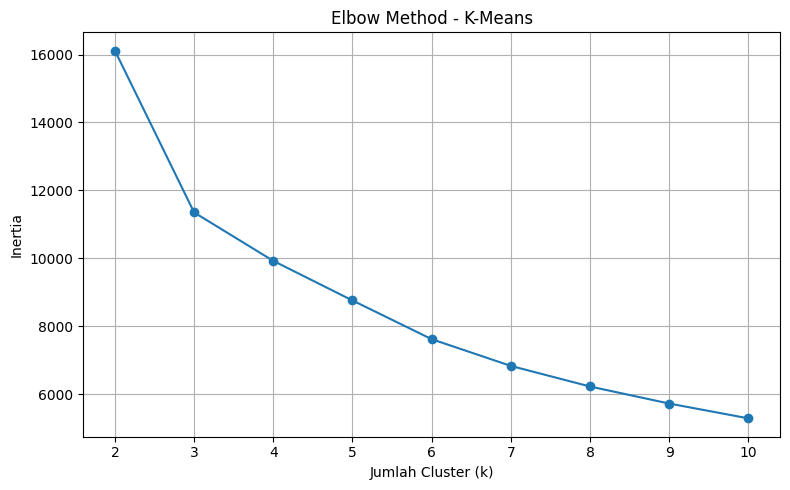

Nilai k berdasarkan KneeLocator: 4


In [16]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.

# Plot grafik Elbow
plt.figure(figsize=(8, 5))
plt.plot(inertia_df["k"], inertia_df["inertia"], marker="o")
plt.xticks(inertia_df["k"])
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method - K-Means")
plt.grid(True)
plt.tight_layout()
plt.show()

# Deteksi elbow secara otomatis menggunakan KneeLocator (opsional)
from kneed import KneeLocator

knee = KneeLocator(
    inertia_df["k"],
    inertia_df["inertia"],
    curve="convex",
    direction="decreasing"
)

print("Nilai k berdasarkan KneeLocator:", knee.elbow)

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [17]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

# Hitung Silhouette Score untuk k = 2 sampai 10
silhouette_results = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_log_scaled)

    score = silhouette_score(X_log_scaled, labels)

    silhouette_results.append({
        "k": k,
        "silhouette_score": score
    })

# Simpan dan tampilkan hasil
silhouette_df = pd.DataFrame(silhouette_results)
print(silhouette_df)

    k  silhouette_score
0   2          0.525262
1   3          0.404634
2   4          0.391827
3   5          0.372504
4   6          0.294380
5   7          0.294202
6   8          0.307684
7   9          0.317249
8  10          0.322683


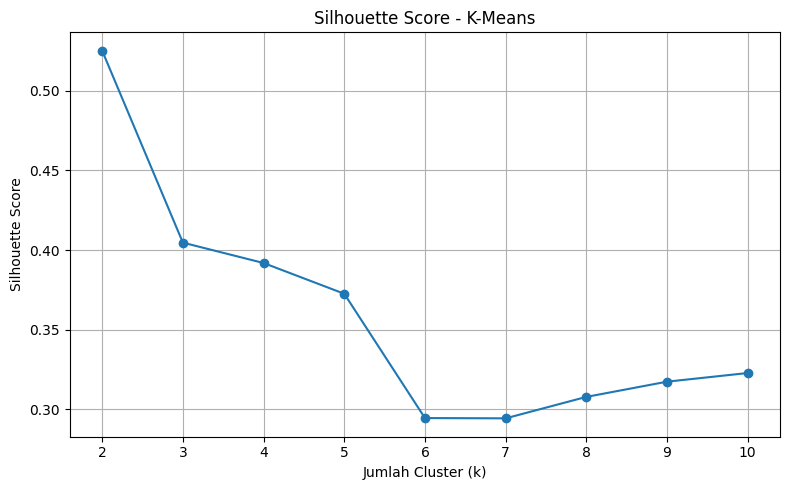

In [18]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.

# Plot Silhouette Score terhadap k
plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_df["k"],
    silhouette_df["silhouette_score"],
    marker="o"
)
plt.xticks(silhouette_df["k"])
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score - K-Means")
plt.grid(True)
plt.tight_layout()
plt.show()

**Pilihan k untuk K-Means:** Berdasarkan Elbow Method, nilai k = 4 terdeteksi sebagai titik siku oleh KneeLocator, yang menunjukkan bahwa penambahan cluster setelah titik tersebut memberikan penurunan inertia yang semakin kecil.

Namun, berdasarkan Silhouette Score, nilai k = 2 memperoleh skor tertinggi sebesar 0,5253, lebih tinggi dibandingkan k = 3 sebesar 0,4046 dan k = 4 sebesar 0,3918. Hal ini menunjukkan bahwa k = 2 menghasilkan pemisahan cluster dan kepadatan anggota cluster yang relatif lebih baik.

Dengan mempertimbangkan kedua metode, **k = 2 dipilih sebagai jumlah cluster terbaik** karena menghasilkan Silhouette Score tertinggi. Sementara itu, k = 4 dapat dipertimbangkan sebagai alternatif apabila dibutuhkan segmentasi yang lebih terperinci, sesuai hasil Elbow Method.

## 3.4 Model K-Means Final

In [19]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

# Latih K-Means final dengan k terbaik
k_terbaik = 2

kmeans_final = KMeans(
    n_clusters=k_terbaik,
    random_state=42,
    n_init=10
)

label_kmeans = kmeans_final.fit_predict(X_log_scaled)

# Simpan label cluster untuk evaluasi
df["cluster_kmeans"] = label_kmeans

In [20]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.

# Profil cluster menggunakan data asli sebelum transformasi log dan scaling
profil_data = X_raw.copy()
profil_data["cluster"] = label_kmeans

# Hitung jumlah anggota setiap cluster
jumlah_anggota = profil_data.groupby("cluster").size().rename("jumlah_anggota")

# Hitung median dan rata-rata setiap fitur per cluster
median_cluster = profil_data.groupby("cluster")[fitur_clustering].median()
mean_cluster = profil_data.groupby("cluster")[fitur_clustering].mean()

# Gabungkan hasil profil cluster
profil_cluster = pd.concat(
    {
        "Median": median_cluster,
        "Rata-rata": mean_cluster
    },
    axis=1
)

profil_cluster = pd.concat(
    [jumlah_anggota, profil_cluster],
    axis=1
)

print("Profil Cluster K-Means (Data Asli):")
display(profil_cluster.round(2))

Profil Cluster K-Means (Data Asli):


,jumlah_anggota,"(Median, num_likes)","(Median, num_loves)","(Median, num_rare_reactions)","(Median, num_comments)","(Median, num_shares)","(Rata-rata, num_likes)","(Rata-rata, num_loves)","(Rata-rata, num_rare_reactions)","(Rata-rata, num_comments)","(Rata-rata, num_shares)"
cluster,,,,,,,,,,,
0,5167,28.0,0.0,0.0,1.0,0.0,98.32,0.43,0.24,5.16,0.84
1,1883,205.0,12.0,3.0,92.0,16.0,282.33,9.07,8.11,70.24,11.77


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [21]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.

# Hitung linkage matrix menggunakan metode Ward
linkage_matrix = linkage(
    X_log_scaled,
    method="ward"
)

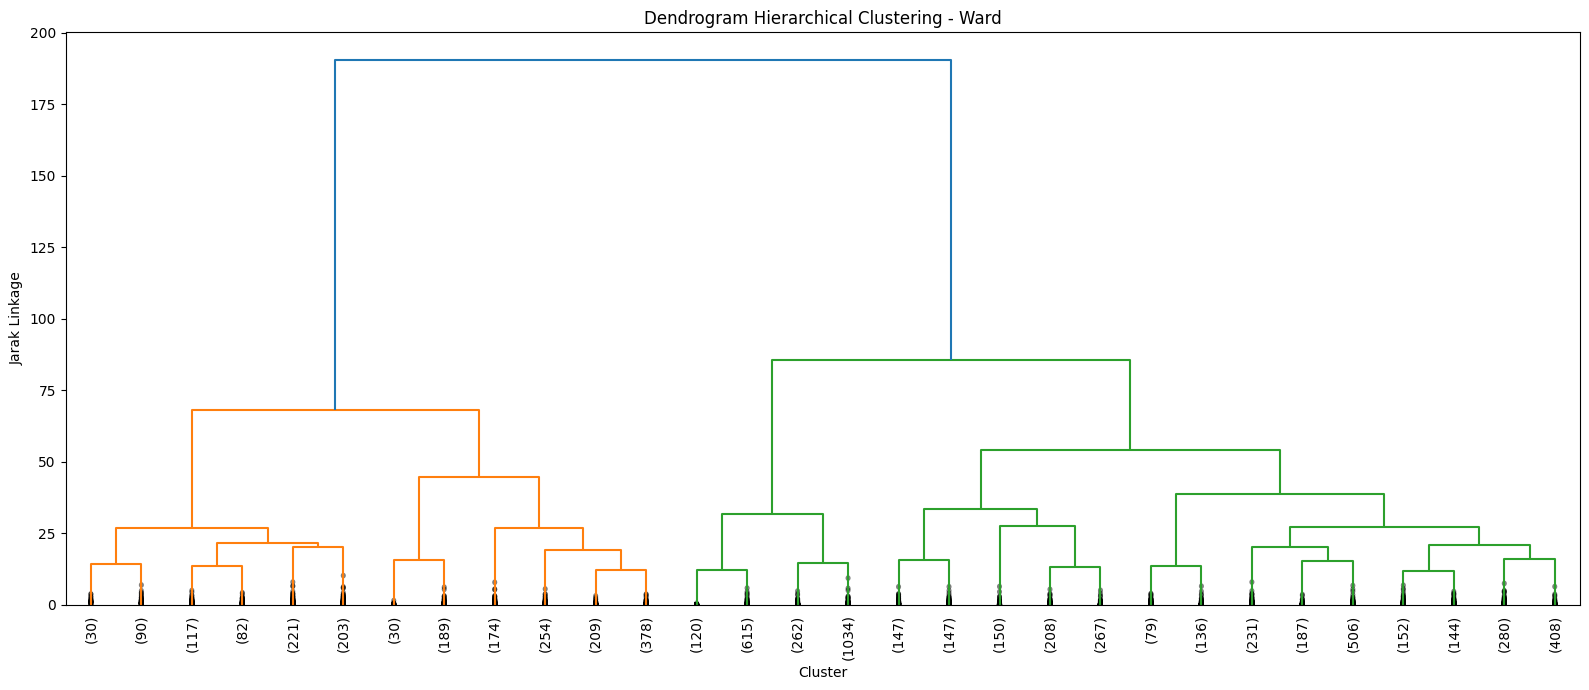

In [22]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.

# Tampilkan dendrogram dengan tampilan yang dibatasi
plt.figure(figsize=(16, 7))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)

plt.title("Dendrogram Hierarchical Clustering - Ward")
plt.xlabel("Cluster")
plt.ylabel("Jarak Linkage")
plt.tight_layout()
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [23]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.

# Latih Agglomerative Clustering dengan empat metode linkage
linkage_methods = ["ward", "complete", "average", "single"]
hasil_hierarchical = {}

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=k_terbaik,
        linkage=method
    )

    labels = model.fit_predict(X_log_scaled)
    hasil_hierarchical[method] = labels

# Simpan label cluster untuk evaluasi
label_ward = hasil_hierarchical["ward"]
label_complete = hasil_hierarchical["complete"]
label_average = hasil_hierarchical["average"]
label_single = hasil_hierarchical["single"]

In [24]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).

# Bandingkan Silhouette Score dan jumlah anggota tiap cluster
hasil_perbandingan = []

for method, labels in hasil_hierarchical.items():
    jumlah = pd.Series(labels).value_counts().sort_index()

    hasil_perbandingan.append({
        "Linkage": method,
        "Silhouette Score": silhouette_score(X_log_scaled, labels),
        "Cluster 0": jumlah.get(0, 0),
        "Cluster 1": jumlah.get(1, 0),
        "Cluster Terbesar (%)": jumlah.max() / len(labels) * 100,
        "Cluster Terkecil (%)": jumlah.min() / len(labels) * 100,
        "Rasio Terbesar:Terkecil": jumlah.max() / jumlah.min()
    })

# Tampilkan dalam satu tabel
tabel_linkage = pd.DataFrame(hasil_perbandingan)

print("Perbandingan Agglomerative Clustering:")
display(tabel_linkage.round(4))

# Tandai linkage dengan cluster sangat tidak seimbang
print("\nPemeriksaan Keseimbangan Cluster:")
for _, row in tabel_linkage.iterrows():
    if row["Cluster Terkecil (%)"] < 5 or row["Rasio Terbesar:Terkecil"] > 10:
        status = "Cluster sangat tidak seimbang"
    else:
        status = "Tidak terlalu timpang berdasarkan batas pemeriksaan"

    print(f'{row["Linkage"]}: {status}')

Perbandingan Agglomerative Clustering:


,Linkage,Silhouette Score,Cluster 0,Cluster 1,Cluster Terbesar (%),Cluster Terkecil (%),Rasio Terbesar:Terkecil
0,ward,0.4985,5073,1977,71.9574,28.0426,2.5660
1,complete,0.4019,6799,251,96.4397,3.5603,27.0876
2,average,0.5275,1405,5645,80.0709,19.9291,4.0178
3,single,0.4715,7049,1,99.9858,0.0142,7049.0000



Pemeriksaan Keseimbangan Cluster:
ward: Tidak terlalu timpang berdasarkan batas pemeriksaan
complete: Cluster sangat tidak seimbang
average: Tidak terlalu timpang berdasarkan batas pemeriksaan
single: Cluster sangat tidak seimbang


**Pilihan linkage untuk Hierarchical Clustering:** Linkage yang dipilih adalah **average linkage** karena menghasilkan Silhouette Score tertinggi sebesar 0,5275 dibandingkan ward (0,4985), complete (0,4019), dan single (0,4715). Pembagian cluster terdiri dari 1.405 dan 5.645 anggota, sehingga masih cukup layak meskipun tidak seimbang sempurna. Complete dan single tidak dipilih karena menghasilkan cluster yang sangat timpang, terutama single yang menempatkan 7.049 data dalam satu cluster dan hanya 1 data pada cluster lainnya.

## 4.3 Model Hierarchical Clustering Final

In [25]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

# Latih Agglomerative Clustering final
hierarchical_final = AgglomerativeClustering(
    n_clusters=k_terbaik,
    linkage="average"
)

label_hierarchical = hierarchical_final.fit_predict(X_log_scaled)

# Simpan label cluster untuk evaluasi
df["cluster_hierarchical"] = label_hierarchical

In [26]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.

# Profil setiap cluster Hierarchical Clustering pada data asli
profil_hierarchical = X_raw.copy()
profil_hierarchical["cluster"] = label_hierarchical

# Hitung jumlah anggota, median, dan rata-rata tiap fitur
jumlah_anggota_h = profil_hierarchical.groupby("cluster").size().rename("jumlah_anggota")

median_h = profil_hierarchical.groupby("cluster")[fitur_clustering].median()
mean_h = profil_hierarchical.groupby("cluster")[fitur_clustering].mean()

# Gabungkan hasil profil cluster
profil_cluster_hierarchical = pd.concat(
    {
        "Median": median_h,
        "Rata-rata": mean_h
    },
    axis=1
)

profil_cluster_hierarchical = pd.concat(
    [jumlah_anggota_h, profil_cluster_hierarchical],
    axis=1
)

print("Profil Cluster Hierarchical Clustering (Data Asli):")
display(profil_cluster_hierarchical.round(2))

Profil Cluster Hierarchical Clustering (Data Asli):


,jumlah_anggota,"(Median, num_likes)","(Median, num_loves)","(Median, num_rare_reactions)","(Median, num_comments)","(Median, num_shares)","(Rata-rata, num_likes)","(Rata-rata, num_loves)","(Rata-rata, num_rare_reactions)","(Rata-rata, num_comments)","(Rata-rata, num_shares)"
cluster,,,,,,,,,,,
0,1405,191.0,12.0,4.0,92.0,16.0,274.22,10.84,9.62,83.83,13.85
1,5645,33.0,0.0,0.0,2.0,0.0,115.92,0.72,0.53,7.29,1.25


# 5. Evaluasi Model

In [28]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.

# Evaluasi K-Means
hasil_kmeans = {
    "Model": "K-Means",
    "Silhouette Score": silhouette_score(X_log_scaled, label_kmeans),
    "Davies-Bouldin Index": davies_bouldin_score(X_log_scaled, label_kmeans),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_log_scaled, label_kmeans)
}

# Evaluasi Hierarchical Clustering
hasil_hierarchical_eval = {
    "Model": "Hierarchical (Average)",
    "Silhouette Score": silhouette_score(X_log_scaled, label_hierarchical),
    "Davies-Bouldin Index": davies_bouldin_score(X_log_scaled, label_hierarchical),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_log_scaled, label_hierarchical)
}

# Sajikan dalam satu tabel perbandingan
tabel_evaluasi = pd.DataFrame([
    hasil_kmeans,
    hasil_hierarchical_eval
])

print("Perbandingan Metrik Evaluasi Internal:")
display(tabel_evaluasi.round(4))

Perbandingan Metrik Evaluasi Internal:


,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.5253,0.7657,8370.4771
1,Hierarchical (Average),0.5275,0.6608,7283.2198


Persentase Varians PCA:
PC1: 69.59%
PC2: 12.03%
Total Varians: 81.62%


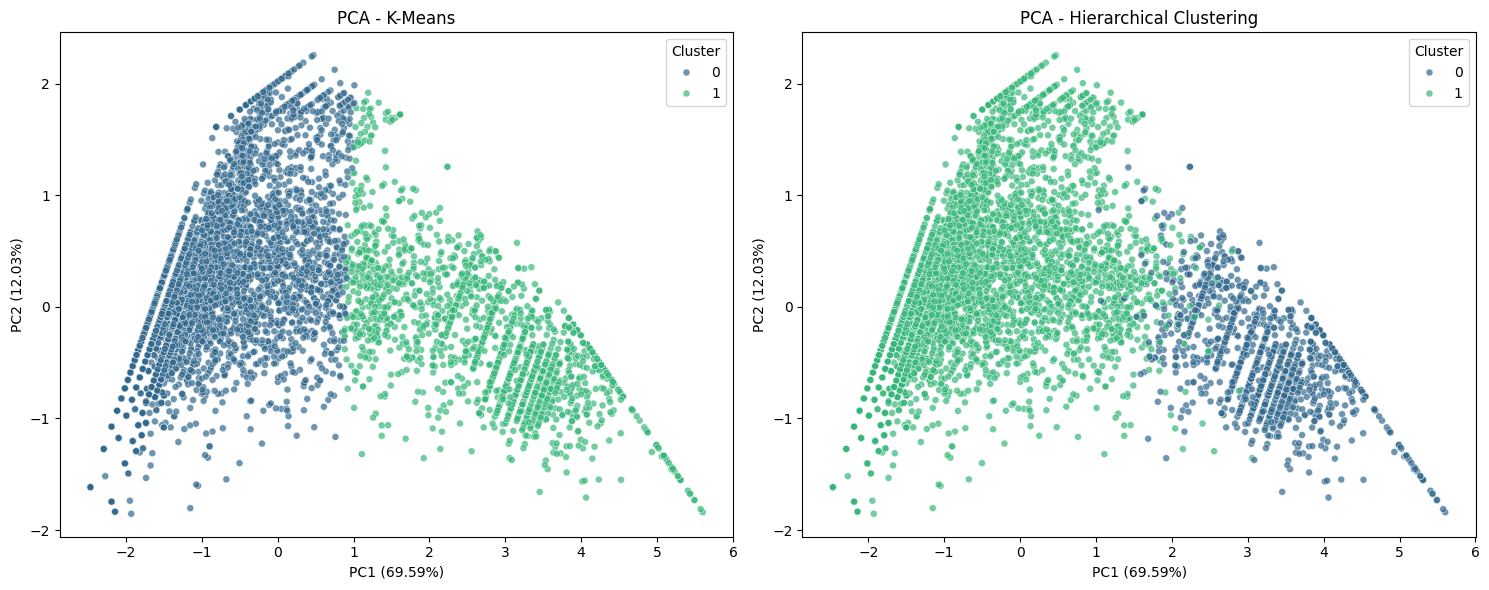

In [30]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.

# PCA menjadi 2 komponen
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_log_scaled)

# Persentase varians yang dijelaskan
explained_variance = pca.explained_variance_ratio_ * 100

print("Persentase Varians PCA:")
print(f"PC1: {explained_variance[0]:.2f}%")
print(f"PC2: {explained_variance[1]:.2f}%")
print(f"Total Varians: {explained_variance.sum():.2f}%")

# Scatter plot K-Means dan Hierarchical Clustering
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=label_kmeans,
    palette="viridis",
    s=25,
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title("PCA - K-Means")
axes[0].set_xlabel(f"PC1 ({explained_variance[0]:.2f}%)")
axes[0].set_ylabel(f"PC2 ({explained_variance[1]:.2f}%)")
axes[0].legend(title="Cluster")

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=label_hierarchical,
    palette="viridis",
    s=25,
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title("PCA - Hierarchical Clustering")
axes[1].set_xlabel(f"PC1 ({explained_variance[0]:.2f}%)")
axes[1].set_ylabel(f"PC2 ({explained_variance[1]:.2f}%)")
axes[1].legend(title="Cluster")

plt.tight_layout()
plt.show()

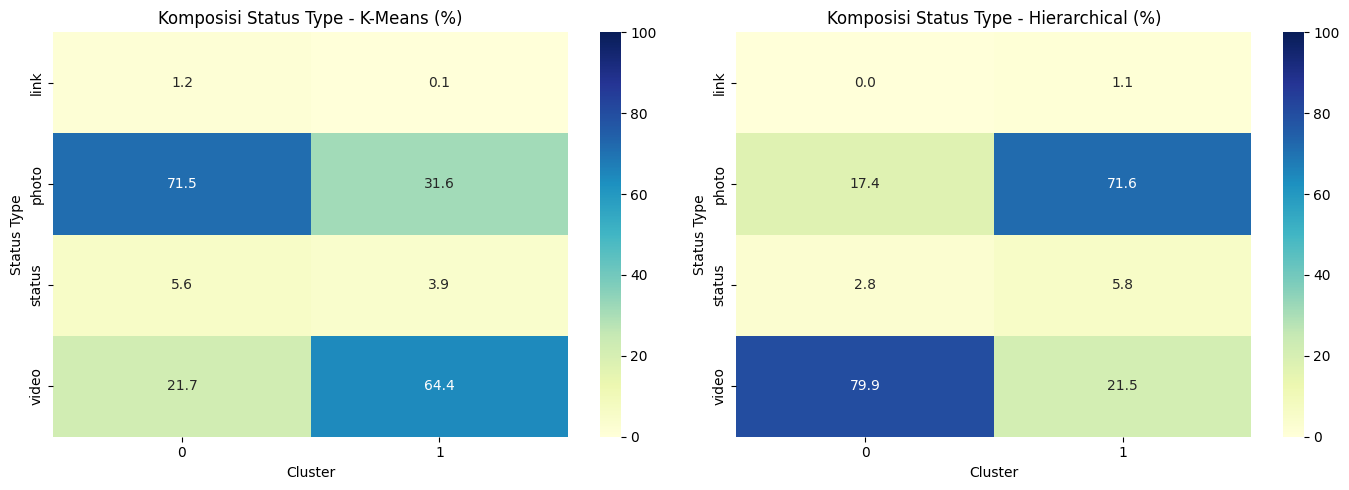

In [31]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.

# Crosstab komposisi status_type per cluster dalam persentase
status_type = df.loc[X_raw.index, "status_type"]

crosstab_kmeans = pd.crosstab(
    status_type,
    pd.Series(label_kmeans, index=X_raw.index, name="Cluster"),
    normalize="columns"
) * 100

crosstab_hierarchical = pd.crosstab(
    status_type,
    pd.Series(label_hierarchical, index=X_raw.index, name="Cluster"),
    normalize="columns"
) * 100

# Heatmap dalam satu baris subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    crosstab_kmeans,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    ax=axes[0]
)
axes[0].set_title("Komposisi Status Type - K-Means (%)")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Status Type")

sns.heatmap(
    crosstab_hierarchical,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    ax=axes[1]
)
axes[1].set_title("Komposisi Status Type - Hierarchical (%)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Status Type")

plt.tight_layout()
plt.show()

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

# Analisis dan Evaluasi Hasil Clustering Dataset Live.csv

## 1. Pengaruh Transformasi Log dan Feature Scaling pada K-Means

Dataset Live.csv memiliki 7.050 baris dan 16 kolom. Setelah menghapus kolom yang seluruhnya kosong dan memisahkan kolom metadata, clustering dilakukan menggunakan lima fitur numerik, yaitu `num_likes`, `num_loves`, `num_rare_reactions`, `num_comments`, dan `num_shares`.

Berdasarkan EDA, distribusi fitur hitungan sangat miring ke kanan (*right-skewed*) dan mengandung banyak nilai ekstrem. Sebagai contoh, `num_comments` memiliki nilai maksimum 20.990, sedangkan `num_angrys` hanya mencapai 31. Selain itu, 94% data `num_angrys` bernilai nol, sementara 1,79% data `num_likes` bernilai nol.

Kondisi tersebut menjadi masalah bagi K-Means karena algoritma ini menentukan cluster berdasarkan jarak Euclidean. Fitur dengan rentang nilai dan varians besar dapat mendominasi perhitungan jarak sehingga fitur lainnya kurang berpengaruh.

Pada eksperimen perbandingan dengan k = 3, diperoleh hasil berikut:

| Versi data | Jumlah anggota cluster | Silhouette Score |
|---|---|---:|
| `X_raw` | 4.762, 770, 1.518 | 0,2938 |
| `X_raw_scaled` | 1.389, 5.629, 32 | 0,5014 |
| `X_log_scaled` | 3.328, 1.486, 2.236 | 0,4046 |

Silhouette Score pada tabel tersebut dihitung menggunakan ruang evaluasi yang sama, yaitu `X_log_scaled`, sesuai rancangan eksperimen.

Hasil pemeriksaan varians menunjukkan bahwa `num_likes` menyumbang 96,66% dari total varians fitur mentah, sedangkan `num_comments` menyumbang 2,90%. Dengan demikian, K-Means pada data mentah berpotensi lebih banyak membentuk cluster berdasarkan jumlah likes daripada keseluruhan pola interaksi.

Feature scaling menggunakan StandardScaler menyamakan skala varians antarf fitur sehingga pengaruh fitur tidak lagi ditentukan semata-mata oleh besar kecilnya satuan. Hal ini meningkatkan Silhouette Score hasil perbandingan dari 0,2938 menjadi 0,5014. Namun, cluster yang dihasilkan masih sangat timpang karena satu cluster hanya memiliki 32 anggota.

Transformasi `log1p`, yang menghitung logaritma natural dari nilai ditambah satu, membantu memampatkan rentang nilai besar tanpa menghilangkan nilai nol. Ketika dilanjutkan dengan StandardScaler, fitur menjadi lebih sebanding dalam perhitungan jarak dan pengaruh nilai ekstrem berkurang.

Pada `X_log_scaled`, jumlah anggota ketiga cluster lebih tersebar, yaitu 3.328, 1.486, dan 2.236. Walaupun Silhouette Score-nya sebesar 0,4046 lebih rendah daripada hasil `X_raw_scaled` dalam pengujian tersebut, distribusi cluster-nya lebih seimbang. Karena itu, pemilihan preprocessing tidak cukup didasarkan pada satu skor saja; bentuk distribusi, proporsi anggota, dan kemudahan interpretasi juga perlu dipertimbangkan.

Secara keseluruhan, transformasi log dan scaling sesuai untuk mengurangi dominasi nilai ekstrem dan perbedaan skala dalam dataset ini. Keduanya penting sebelum menerapkan algoritma clustering berbasis jarak.

## 2. Pemilihan Fitur dan Penanganan Redundansi

Sebelum clustering, fitur diperiksa untuk menemukan kolom redundan dan fitur yang didominasi nilai nol. Hasil pemeriksaan menunjukkan bahwa `num_reactions` memiliki korelasi 0,99 dengan `num_likes`. Selain itu, pada 5.497 dari 7.050 baris, nilai `num_reactions` sama dengan jumlah komponen reaksi yang diperiksa.

Jika fitur-fitur tersebut dipertahankan sekaligus, informasi yang serupa dapat memperoleh bobot berlebihan dalam perhitungan jarak. Oleh karena itu, `num_reactions` tidak digunakan sebagai fitur clustering.

Proporsi nilai nol pada sejumlah fitur emoji juga sangat tinggi: `num_wows` sebesar 75,29%, `num_hahas` sebesar 83,91%, `num_sads` sebesar 91,39%, dan `num_angrys` sebesar 94%. Keempat fitur tersebut digabungkan menjadi `num_rare_reactions` untuk mengurangi dimensi dan sparsity, sambil tetap mempertahankan informasi mengenai reaksi emoji yang lebih jarang muncul.

Fitur yang akhirnya digunakan adalah:

| Fitur | Alasan pemilihan |
|---|---|
| `num_likes` | Mewakili jumlah likes dan memiliki proporsi nilai nol rendah, yaitu 1,79%. |
| `num_loves` | Mewakili reaksi love yang memiliki makna interaksi tersendiri, meskipun 60% nilainya nol. |
| `num_rare_reactions` | Menggabungkan empat jenis reaksi yang relatif jarang agar informasi reaksinya tetap tersedia dengan jumlah fitur lebih sedikit. |
| `num_comments` | Mewakili interaksi melalui komentar; 30,06% nilainya nol, tetapi fitur ini tetap relevan. |
| `num_shares` | Mewakili penyebaran konten; meskipun 55,48% nilainya nol, fitur ini menunjukkan pola berbagi posting. |

Kolom `status_id` dihapus karena hanya berfungsi sebagai identitas posting. Kolom `status_type` dan `status_published` dipisahkan dari fitur clustering agar dapat digunakan dalam interpretasi hasil. Empat kolom yang seluruh nilainya kosong juga dihapus.

Outlier ekstrem diperiksa dan ditangani menggunakan metode capping dengan batas 3 × IQR. Selanjutnya, transformasi log dan feature scaling diterapkan pada lima fitur terpilih. Dengan demikian, fitur clustering seluruhnya bersifat numerik dan lebih sesuai untuk perhitungan jarak.

## 3. Penentuan Jumlah Cluster Optimal K-Means

Jumlah cluster optimal ditentukan melalui Elbow Method dan Silhouette Score. Kedua metode memberikan sudut pandang yang berbeda.

### 3.1 Elbow Method

Nilai inertia menurun seiring bertambahnya jumlah cluster. KneeLocator mendeteksi titik elbow pada **k = 4**. Penurunan inertia paling besar terjadi ketika jumlah cluster bertambah dari dua menjadi tiga, kemudian penurunannya semakin kecil.

Nilai inertia pada beberapa titik adalah:

| k | Inertia |
|---:|---:|
| 2 | 16.113,29 |
| 3 | 11.348,81 |
| 4 | 9.921,99 |
| 5 | 8.756,25 |
| 6 | 7.615,85 |

Hasil tersebut menunjukkan bahwa k = 4 merupakan kandidat jumlah cluster berdasarkan deteksi elbow otomatis. Penambahan cluster setelah titik tersebut cenderung memberikan pengurangan inertia yang semakin kecil.

### 3.2 Silhouette Score

Silhouette Score tertinggi diperoleh pada k = 2 sebesar **0,5253**. Setelah itu, skor cenderung menurun ketika jumlah cluster ditambah.

| k | Silhouette Score |
|---:|---:|
| 2 | 0,5253 |
| 3 | 0,4046 |
| 4 | 0,3918 |
| 5 | 0,3725 |
| 6 | 0,2944 |
| 7 | 0,2942 |
| 8 | 0,3077 |
| 9 | 0,3172 |
| 10 | 0,3227 |

Silhouette Score mengukur seberapa baik suatu data berada dalam cluster-nya dibandingkan dengan cluster terdekat. Semakin tinggi nilainya, semakin baik pemisahan cluster relatif terhadap kepadatan anggotanya.

### 3.3 Keputusan jumlah cluster

Kedua metode tidak menghasilkan kesimpulan yang sama. Elbow Method menunjukkan k = 4, sedangkan Silhouette Score tertinggi diperoleh pada k = 2.

Dalam eksperimen ini, **k = 2 dipilih sebagai jumlah cluster final** karena menghasilkan Silhouette Score tertinggi dan memberikan pembagian kelompok interaksi yang mudah diinterpretasikan. K = 4 tetap dapat dipertimbangkan jika tujuan analisis adalah memperoleh segmentasi yang lebih terperinci, tetapi hal tersebut memerlukan evaluasi lanjutan.

## 4. Perbandingan Metode Linkage Hierarchical Clustering

Agglomerative Hierarchical Clustering diuji menggunakan linkage ward, complete, average, dan single. Keempat metode menggunakan jumlah cluster yang sama, yaitu k = 2, dengan data `X_log_scaled`.

Hasil eksperimennya adalah:

| Linkage | Silhouette Score | Cluster 0 | Cluster 1 | Interpretasi keseimbangan |
|---|---:|---:|---:|---|
| Ward | 0,4985 | 5.073 | 1.977 | Relatif seimbang |
| Complete | 0,4019 | 6.799 | 251 | Sangat timpang |
| Average | **0,5275** | 1.405 | 5.645 | Cukup layak, tetapi tidak seimbang sempurna |
| Single | 0,4715 | 7.049 | 1 | Sangat timpang |

**Average linkage dipilih sebagai metode final** karena menghasilkan Silhouette Score tertinggi di antara keempat linkage. Pembagian anggotanya juga masih menghasilkan dua kelompok yang dapat dianalisis, meskipun cluster terbesar memiliki sekitar empat kali jumlah anggota cluster terkecil.

Ward menghasilkan kelompok yang lebih seimbang, tetapi Silhouette Score-nya lebih rendah daripada average. Complete menghasilkan cluster yang sangat timpang, dengan 6.799 anggota dalam satu cluster dan hanya 251 anggota pada cluster lainnya.

Single linkage menghasilkan satu cluster berisi 7.049 data dan satu cluster berisi satu data. Karakteristik ini berkaitan dengan *chaining effect*: penggabungan didasarkan pada jarak minimum antarpasangan titik sehingga rangkaian titik yang saling berdekatan dapat membentuk kelompok yang sangat besar, sementara sebagian kecil titik terpisah. Walaupun Silhouette Score-nya sebesar 0,4715, pembagian seperti ini kurang bermanfaat untuk segmentasi dua kelompok.

Dengan mempertimbangkan pemisahan cluster dan ukuran kelompok, average linkage dinilai paling sesuai untuk eksperimen ini.

## 5. Perbandingan Performa K-Means dan Hierarchical Clustering

Evaluasi final menggunakan Silhouette Score, Davies-Bouldin Index, dan Calinski-Harabasz Score pada `X_log_scaled`.

| Model | Silhouette Score | Davies-Bouldin Index | Calinski-Harabasz Score |
|---|---:|---:|---:|
| K-Means | 0,5253 | 0,7657 | 8.370,4771 |
| Hierarchical (Average) | **0,5275** | **0,6608** | 7.283,2198 |

Interpretasi masing-masing metrik adalah sebagai berikut:

- **Silhouette Score:** Hierarchical sedikit lebih baik dengan 0,5275 dibandingkan K-Means dengan 0,5253. Selisihnya sangat kecil, yaitu 0,0022.
- **Davies-Bouldin Index:** Hierarchical lebih baik karena nilainya lebih rendah, yaitu 0,6608 dibandingkan 0,7657. Nilai yang lebih rendah mengindikasikan cluster yang relatif lebih kompak dan lebih terpisah.
- **Calinski-Harabasz Score:** K-Means memperoleh nilai lebih tinggi, yaitu 8.370,4771 dibandingkan 7.283,2198. Berdasarkan metrik ini, K-Means menghasilkan rasio dispersi antarkelompok terhadap dispersi dalam kelompok yang lebih tinggi.

Tidak ada satu algoritma yang unggul pada seluruh metrik. Hierarchical unggul pada Silhouette Score dan Davies-Bouldin Index, sedangkan K-Means unggul pada Calinski-Harabasz Score.

Karena perbedaan Silhouette Score hanya 0,0022, performa kedua metode dapat dikatakan relatif serupa berdasarkan metrik tersebut. Namun, tidak dapat disimpulkan bahwa perbedaannya signifikan secara statistik tanpa pengujian tambahan.

### 5.1 Visualisasi PCA

PCA digunakan untuk memproyeksikan data ke dua komponen agar struktur cluster dapat dilihat secara visual. Kedua komponen menjelaskan varians sebagai berikut:

| Komponen | Varians yang dijelaskan |
|---|---:|
| PC1 | 69,59% |
| PC2 | 12,03% |
| **Total** | **81,62%** |

Dua komponen tersebut menjelaskan 81,62% varians data, sehingga visualisasi cukup representatif terhadap variasi keseluruhan, meskipun masih ada 18,38% varians pada komponen lainnya.

Pada scatter plot PCA, kedua algoritma memperlihatkan pola umum yang serupa: terdapat kelompok posting dengan interaksi relatif rendah dan kelompok dengan interaksi relatif tinggi. Pemisahan terutama terlihat sepanjang PC1, tetapi sebagian titik masih berada di area transisi atau saling berdekatan.

Nomor cluster pada kedua algoritma tidak harus sama maknanya. Misalnya, cluster 0 pada K-Means merupakan kelompok interaksi rendah, sedangkan cluster 0 pada Hierarchical merupakan kelompok interaksi tinggi. Nomor cluster hanyalah label yang diberikan algoritma, bukan urutan tingkat interaksi.

Secara keseluruhan, visualisasi PCA mendukung kesimpulan bahwa kedua algoritma menemukan segmentasi utama yang serupa. Perbedaan terletak pada batas pemisahan dan jumlah anggota masing-masing kelompok.

## 6. Karakteristik dan Interpretasi Setiap Cluster

Profil cluster dibuat berdasarkan data fitur asli sebelum transformasi log dan scaling. Median digunakan sebagai ukuran utama karena distribusi fitur sangat miring dan memiliki nilai ekstrem. Komposisi `status_type` dihitung sebagai persentase di dalam masing-masing cluster, sehingga membantu menjelaskan jenis posting yang dominan pada tiap kelompok.

### 6.1 Profil K-Means

| Karakteristik | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Jumlah anggota | 5.167 (73,29%) | 1.883 (26,71%) |
| Median `num_likes` | 28 | 205 |
| Median `num_loves` | 0 | 12 |
| Median `num_rare_reactions` | 0 | 3 |
| Median `num_comments` | 1 | 92 |
| Median `num_shares` | 0 | 16 |
| Persentase foto | 71,5% | 31,6% |
| Persentase video | 21,7% | 64,4% |

**Cluster 0 — “Posting dengan Interaksi Rendah, Didominasi Foto”**

Cluster ini berisi 5.167 posting atau sekitar 73,29% dari dataset. Median likes hanya 28, median komentar 1, dan median shares 0. Median reaksi love maupun reaksi emoji gabungan juga nol. Komposisinya didominasi foto sebesar 71,5%.

Karakteristik tersebut menggambarkan kelompok posting yang umumnya memperoleh interaksi rendah. Banyak posting di cluster ini mendapatkan sedikit komentar dan tidak dibagikan.

**Cluster 1 — “Posting dengan Interaksi Tinggi, Didominasi Video”**

Cluster ini berisi 1.883 posting atau 26,71% dari dataset. Median likes mencapai 205, median komentar 92, median shares 16, dan median love 12. Sebanyak 64,4% anggotanya berupa video.

Dibandingkan Cluster 0, kelompok ini menunjukkan pola interaksi yang jauh lebih tinggi. Komentar, reaksi, dan pembagian posting juga lebih menonjol. Video merupakan jenis konten dominan di kelompok ini.

### 6.2 Profil Hierarchical Clustering

| Karakteristik | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Jumlah anggota | 1.405 (19,93%) | 5.645 (80,07%) |
| Median `num_likes` | 191 | 33 |
| Median `num_loves` | 12 | 0 |
| Median `num_rare_reactions` | 4 | 0 |
| Median `num_comments` | 92 | 2 |
| Median `num_shares` | 16 | 0 |
| Persentase foto | 17,4% | 71,6% |
| Persentase video | 79,9% | 21,5% |

**Cluster 0 — “Posting dengan Interaksi Tinggi, Sangat Didominasi Video”**

Cluster ini berisi 1.405 posting atau 19,93% dari dataset. Median likes mencapai 191, median komentar 92, median shares 16, median love 12, dan median reaksi emoji gabungan 4.

Sebanyak 79,9% anggotanya berupa video. Kombinasi median interaksi yang tinggi dan dominasi video menunjukkan bahwa cluster ini menangkap kelompok posting yang memiliki tingkat interaksi tinggi dengan pemisahan yang lebih kuat terhadap jenis konten video.

**Cluster 1 — “Posting dengan Interaksi Rendah, Didominasi Foto”**

Cluster ini berisi 5.645 posting atau 80,07% dari dataset. Median likes hanya 33, median komentar 2, dan median shares 0. Reaksi love dan reaksi emoji gabungan juga memiliki median nol.

Komposisinya didominasi foto sebesar 71,6%, dengan video sebesar 21,5%. Oleh karena itu, kelompok ini dapat ditafsirkan sebagai posting yang umumnya memiliki interaksi lebih rendah dan lebih banyak berupa foto.

### 6.3 Perbandingan interpretasi kedua model

Kedua algoritma memberikan temuan yang konsisten dalam hal karakteristik utama: satu kelompok berisi posting dengan interaksi rendah dan didominasi foto, sedangkan kelompok lainnya memiliki interaksi relatif tinggi dan didominasi video.

Perbedaannya terdapat pada proporsi anggota dan dominasi jenis konten pada kelompok interaksi tinggi. K-Means membentuk cluster interaksi tinggi sebanyak 1.883 posting dengan 64,4% video. Sementara itu, Hierarchical membentuk cluster interaksi tinggi sebanyak 1.405 posting dengan 79,9% video.

Hal ini menunjukkan bahwa average linkage menghasilkan kelompok berinteraksi tinggi yang lebih kecil dan lebih terkonsentrasi pada video. K-Means, sebaliknya, memasukkan lebih banyak posting ke kelompok interaksi tinggi.

Interpretasi tersebut bersifat deskriptif dan tidak membuktikan bahwa jenis konten video secara langsung menyebabkan peningkatan interaksi. Clustering mengelompokkan posting berdasarkan kemiripan pola interaksinya, sedangkan `status_type` digunakan setelahnya untuk membantu memahami karakteristik kelompok.

## 7. Kelebihan dan Kekurangan K-Means dan Hierarchical Clustering

| Aspek | K-Means | Hierarchical Clustering |
|---|---|---|
| Penentuan jumlah cluster | Memerlukan nilai k sejak awal. Elbow Method dan Silhouette Score digunakan untuk memilihnya. | Dapat membentuk dendrogram untuk membantu menentukan jumlah cluster melalui pemotongan pohon. Model final tetap memerlukan jumlah cluster atau ketinggian pemotongan. |
| Bentuk cluster | Cenderung cocok untuk cluster yang relatif kompak dan berbentuk mendekati bulat dalam ruang fitur. | Fleksibel terhadap struktur pengelompokan, bergantung pada metode linkage. |
| Sensitivitas terhadap skala dan outlier | Sensitif terhadap perbedaan skala, nilai ekstrem, dan pemilihan centroid awal. | Sensitif terhadap skala, metrik jarak, linkage, dan pola outlier. Single linkage juga dapat mengalami chaining effect. |
| Interpretasi | Menghasilkan centroid yang dapat menggambarkan karakteristik rata-rata cluster. | Dendrogram memberikan gambaran hubungan penggabungan antarkelompok secara bertingkat. |
| Waktu komputasi | Umumnya lebih cepat dan mudah diterapkan pada dataset besar karena prosesnya iteratif. | Umumnya membutuhkan komputasi dan memori lebih besar karena harus mengolah hubungan jarak atau penggabungan antarkelompok. |
| Kelebihan utama | Efisien, sederhana, dan cocok untuk membagi banyak data ke dalam sejumlah kelompok. | Menampilkan struktur hierarki serta memungkinkan eksplorasi berbagai jumlah cluster dan linkage. |
| Kekurangan utama | Harus menentukan k terlebih dahulu dan hasilnya dapat berubah akibat inisialisasi atau karakteristik data. | Lebih berat dari sisi komputasi dan pilihan linkage dapat menghasilkan pembagian yang sangat berbeda. |

Untuk dataset berukuran 7.050 baris ini, K-Means lebih praktis dari sisi efisiensi. Hierarchical Clustering memberikan kelebihan berupa dendrogram dan fleksibilitas dalam mengeksplorasi struktur penggabungan kelompok. Namun, pemilihan linkage harus diperhatikan karena single dan complete menghasilkan pembagian yang sangat timpang dalam eksperimen ini.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

## Kesimpulan dan Saran

### Kesimpulan

Berdasarkan eksperimen clustering pada dataset Live.csv yang terdiri dari 7.050 posting Facebook, dapat disimpulkan bahwa algoritma K-Means dan Hierarchical Clustering mampu mengelompokkan posting berdasarkan pola interaksi, meliputi jumlah likes, love, reaksi emoji lainnya, komentar, dan shares.

Tahap preprocessing berperan penting karena data memiliki distribusi yang sangat miring ke kanan, perbedaan skala fitur, dan banyak nilai nol pada fitur reaksi emoji. Kolom yang seluruhnya kosong dihapus, fitur yang redundan tidak digunakan, sedangkan fitur reaksi yang jarang muncul digabungkan menjadi `num_rare_reactions`. Transformasi `log1p` dan StandardScaler diterapkan agar perhitungan jarak tidak terlalu didominasi fitur dengan rentang nilai besar.

Pada K-Means, Elbow Method melalui KneeLocator menunjukkan titik siku pada k = 4, sedangkan Silhouette Score tertinggi diperoleh pada k = 2, yaitu 0,5253. Oleh karena itu, k = 2 dipilih sebagai jumlah cluster final. Pada Hierarchical Clustering, average linkage memberikan Silhouette Score tertinggi di antara empat metode yang diuji, yaitu 0,5275. Sebaliknya, single linkage menghasilkan satu cluster yang hampir mencakup seluruh data dan satu cluster yang hanya berisi satu data, sehingga kurang sesuai untuk segmentasi ini.

Berdasarkan evaluasi internal, kedua model menunjukkan performa yang relatif serupa. Hierarchical Clustering sedikit lebih unggul pada Silhouette Score dan Davies-Bouldin Index, sedangkan K-Means menghasilkan Calinski-Harabasz Score yang lebih tinggi. Visualisasi PCA menunjukkan pola umum yang konsisten, yaitu pemisahan posting dengan interaksi relatif rendah dan posting dengan interaksi relatif tinggi. Dua komponen PCA menjelaskan 81,62% varians data.

Interpretasi profil cluster juga menunjukkan pola yang serupa pada kedua model. Kelompok interaksi rendah didominasi posting foto, dengan median likes, komentar, reaksi emoji, dan shares yang relatif kecil. Sebaliknya, kelompok interaksi tinggi memiliki median interaksi yang lebih besar dan didominasi posting video. Pada K-Means, kelompok interaksi tinggi berisi 1.883 posting, sedangkan pada Hierarchical Clustering kelompok tersebut berisi 1.405 posting dan memiliki proporsi video yang lebih besar.

Dengan demikian, kedua algoritma dapat digunakan untuk segmentasi pola interaksi posting Facebook. K-Means relatif praktis dan efisien, sementara Hierarchical Clustering memberikan informasi tambahan melalui struktur dendrogram. Namun, hasil clustering hanya menunjukkan hubungan dan kemiripan karakteristik data, bukan membuktikan bahwa jenis posting tertentu menyebabkan peningkatan interaksi.

### Saran untuk Eksperimen Selanjutnya

1. **Menganalisis pola berdasarkan waktu posting.** Kolom `status_published` dapat dimanfaatkan untuk membandingkan pola interaksi pada periode yang berbeda, misalnya sebelum dan sesudah tahun 2016. Fitur jam, hari, bulan, atau tahun posting juga dapat diuji untuk mengetahui apakah pola interaksi berbeda menurut waktu publikasi.

2. **Menguji algoritma clustering lain.** DBSCAN dapat dicoba untuk mendeteksi kelompok dengan bentuk yang tidak beraturan dan mengidentifikasi data yang dianggap noise. Gaussian Mixture Model dapat digunakan sebagai alternatif yang menghasilkan keanggotaan cluster berdasarkan probabilitas. Hasilnya perlu dibandingkan dengan model saat ini menggunakan metrik yang sesuai.

3. **Menguji variasi hyperparameter.** Pada K-Means, nilai `n_init`, metode inisialisasi `init`, dan `random_state` dapat divariasikan untuk menguji kestabilan hasil. Untuk Hierarchical Clustering, pengujian dapat diperluas pada beberapa jumlah cluster dan metode linkage lainnya jika relevan.

4. **Mengevaluasi pemilihan dan penggabungan fitur.** Penggabungan empat jenis reaksi emoji menjadi `num_rare_reactions` mengurangi jumlah fitur, tetapi berpotensi menyembunyikan perbedaan pola antara reaksi wow, haha, sad, dan angry. Eksperimen lanjutan dapat membandingkan hasil clustering dengan dan tanpa penggabungan fitur tersebut, serta menguji pengurangan fitur yang redundan berdasarkan korelasi dan relevansi analisis.

5. **Menguji pengaruh reduksi dimensi.** PCA pada eksperimen ini digunakan untuk visualisasi dua dimensi. Pada penelitian berikutnya, PCA dapat diuji sebagai preprocessing sebelum clustering, kemudian hasilnya dibandingkan dengan clustering pada fitur yang telah ditransformasi log dan diskalakan tanpa PCA. Hal ini dapat membantu mengevaluasi apakah pengurangan dimensi mempertahankan struktur cluster atau justru menghilangkan informasi penting.

6. **Menguji kestabilan dan interpretabilitas cluster.** Pemilihan model sebaiknya tidak hanya didasarkan pada Silhouette Score, Davies-Bouldin Index, atau Calinski-Harabasz Score, tetapi juga mempertimbangkan ukuran cluster, kestabilan hasil, serta kemudahan menjelaskan karakteristik setiap kelompok. Evaluasi tambahan dapat dilakukan dengan mengulang eksperimen pada beberapa konfigurasi atau subset data.

Secara keseluruhan, eksperimen lanjutan diharapkan dapat menghasilkan segmentasi yang lebih stabil, informatif, dan sesuai dengan tujuan analisis pola interaksi posting Facebook.